# GTA Tactics — analisi del colpo

Questo notebook gioca migliaia di colpi con il motore di `colpo.py`. Dopo l'aggiunta della **situazione di partenza** (un membro fuori gioco, due attrezzi in magazzino, uno introvabile, quattro mezze giornate) risponde a quattro domande:

1. Un piano dà esiti sfumati o solo "riuscito / fallito"?
2. **Informarsi rende più che andare al buio?** È la domanda che conta.
3. La situazione di partenza cambia davvero il piano giusto?
4. I piani B scattano?

Tutto si misura sul **conto finale** in migliaia di euro. Il giocatore automatico non dà ordini dal vivo: fa solo ripetere le prove fallite di sala, uscita e fuga, finché ha interventi. Non usa piani B.

Se cambi un numero nel blocco `TARATURA` di `colpo.py`, riesegui tutto dall'inizio (Kernel → Restart & Run All). Ci mette circa un minuto e mezzo.

In [1]:
import collections, random, statistics as st
from multiprocessing import Pool
import pandas as pd
import matplotlib.pyplot as plt
import colpo as C

BLU, INCHIOSTRO, GRIGIO = "#2a78d6", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c2",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "text.color": INCHIOSTRO, "axes.labelcolor": GRIGIO,
    "xtick.color": GRIGIO, "ytick.color": GRIGIO, "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "figure.dpi": 110,
})
pd.options.display.max_colwidth = 120
ISTINTO = C.Istinto()

def barre(ax, etichette, valori, titolo, fmt="{:.0%}"):
    y = list(range(len(etichette)))
    ax.barh(y, valori, height=0.55, color=BLU)
    ax.set_yticks(y); ax.set_yticklabels(etichette); ax.invert_yaxis()
    ax.set_title(titolo); ax.grid(axis="y", visible=False); ax.tick_params(length=0)
    largo = max(max(valori), 1e-9)
    for i, v in enumerate(valori):
        ax.text(v + largo * 0.02, i, fmt.format(v), va="center", color=INCHIOSTRO, fontsize=9)
    ax.set_xlim(0, largo * 1.18); ax.set_xticklabels([])

## 1. Una situazione, un piano, mille colpi

Scegli un numero di colpo (lo stesso che dai a `colpo.py`) e scrivi il piano che vuoi mettere alla prova. La cella stampa la situazione e rifiuta i piani impossibili quel giorno.

**Cosa cercare:** una distribuzione larga, con il grosso sui colpi "riusciti a metà" o "sporchi". Se quasi tutto cade su un solo verdetto, il colpo è binario.

Disponibili: nico (normale), vera (normale), tony (normale), lea (a pezzi) | fuori gioco: samir
Magazzino:   auto, silenziata | in piazza: fucile, trapano, scanner | introvabile: disturbatore
Fatti:       guardia, allarme, cassaforte, affluenza | condizioni: allarme, guardia, ferito, sirene | risposte: fuori, ostaggio, lascia, continua


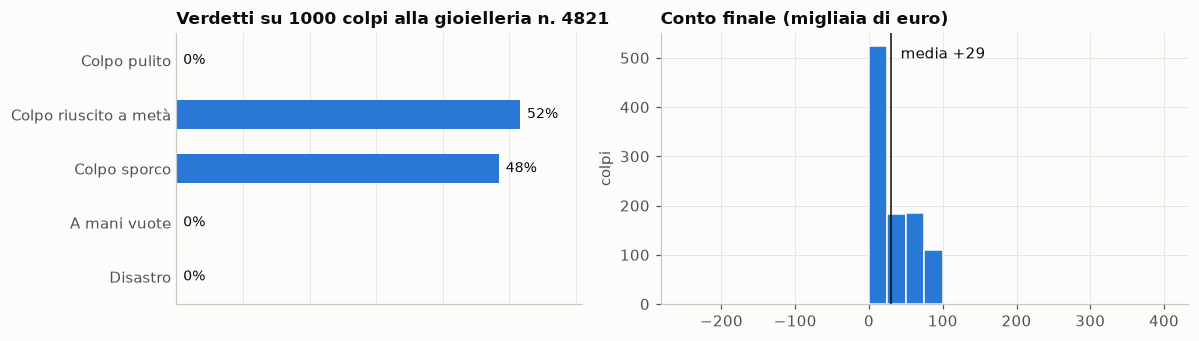

Spesa in attrezzi 10 mila · conto medio +29 mila · in perdita 0% dei colpi · allarme 0% · calore medio 5.9


In [2]:
COLPO = 4821
sc = C.genera_scenario(COLPO)
print("Disponibili:", ", ".join(f"{p} ({C.FORMA[sc.forma[p]]})" for p in sc.disponibili()), "| fuori gioco:", ", ".join(sc.assenti))
print("Magazzino:  ", ", ".join(sorted(sc.magazzino)), "| in piazza:", ", ".join(sc.in_piazza()), "| introvabile:", ", ".join(sc.introvabili))
print("Fatti:      ", ", ".join(C.FATTI), "| condizioni:", ", ".join(C.CONDIZIONI), "| risposte:", ", ".join(C.RISPOSTE))

MIO_PIANO = C.Piano(
    sala="vera", cassaforte="nico", volante="lea",
    equip=frozenset({"silenziata", "auto", "scanner"}),
    sopralluoghi=frozenset({"guardia", "allarme", "cassaforte"}),
    riposi=("lea",),
    battute=2,
    piani_b={"allarme": "fuori", "sirene": "fuori"},
)
assert not MIO_PIANO.errori(sc), MIO_PIANO.errori(sc)

r = random.Random(1)
esiti = [C.gioca(sc, MIO_PIANO, r.random(), ISTINTO) for _ in range(1000)]
media = st.mean(e.conto for e in esiti)
ordine = ["COLPO PULITO", "COLPO RIUSCITO A METÀ", "COLPO SPORCO", "A MANI VUOTE", "DISASTRO"]
quote = collections.Counter(e.verdetto for e in esiti)

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [1, 1.3]})
barre(a, [v.capitalize() for v in ordine], [quote[v] / len(esiti) for v in ordine], f"Verdetti su 1000 colpi alla gioielleria n. {COLPO}")
b.hist([e.conto for e in esiti], bins=range(-250, 401, 25), color=BLU, edgecolor="#fcfcfb", linewidth=1)
b.axvline(media, color=INCHIOSTRO, linewidth=1)
b.text(media, b.get_ylim()[1] * 0.95, f"  media {media:+.0f}", color=INCHIOSTRO, va="top")
b.set_title("Conto finale (migliaia di euro)"); b.set_ylabel("colpi")
plt.tight_layout(); plt.show()
print(f"Spesa in attrezzi {MIO_PIANO.spesa(sc)} mila · conto medio {media:+.0f} mila · in perdita {sum(e.conto < 0 for e in esiti)/len(esiti):.0%} dei colpi · "
      f"allarme {sum(e.allarme for e in esiti)/len(esiti):.0%} · calore medio {st.mean(e.calore for e in esiti):.1f}")

## 2. Informarsi rende più che andare al buio?

Per 24 situazioni di partenza diverse si confrontano tre modi di usare le quattro mezze giornate:

- **Al buio**: nessun sopralluogo, quattro riposi. Si sceglie il piano migliore in media su tutte le gioiellerie possibili.
- **Un fatto**: un sopralluogo e tre riposi. Il piano si sceglie sapendo quel fatto.
- **Tutto**: quattro sopralluoghi, nessun riposo. Il piano si sceglie sapendo com'è fatta la gioielleria.

Ogni piano viene scelto su un gruppo di colpi e misurato su colpi nuovi, così chi ha solo avuto fortuna non viene premiato.

**Cosa cercare:** barre nettamente sopra lo zero. Il progetto dice che un colpo "non si può fare alla cieca": se le barre stanno a zero o sotto, le regole dicono il contrario.

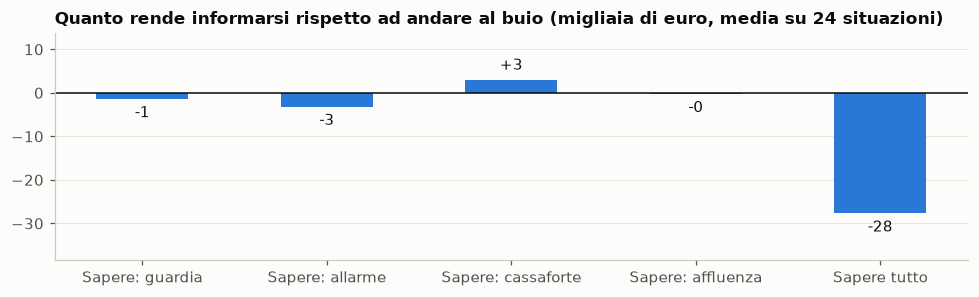

Al buio, con quattro riposi: +75 mila di media.
SEGNALE: «Sapere: guardia» rende -1 mila rispetto al buio. Non batte un riposo in più.
SEGNALE: «Sapere: allarme» rende -3 mila rispetto al buio. Non batte un riposo in più.
SEGNALE: «Sapere: cassaforte» rende +3 mila rispetto al buio. Non batte un riposo in più.
SEGNALE: «Sapere: affluenza» rende -0 mila rispetto al buio. Non batte un riposo in più.
SEGNALE: «Sapere tutto» rende -28 mila rispetto al buio. Non batte un riposo in più.


,colpo,fuori gioco,magazzino,introvabile,piano al buio,al buio,sapendo tutto,"al buio, stesse gioiellerie"
0,100,tony,fucile+scanner,auto,vera/lea/samir · scanner · 3 batt.,69,57,54
1,101,samir,disturbatore+scanner,trapano,tony/nico/lea · disturbatore · 3 batt.,70,40,75
2,102,tony,scanner+trapano,disturbatore,vera/lea/samir · scanner · 2 batt.,64,56,76
3,103,nico,auto+trapano,disturbatore,tony/lea/samir · auto · 3 batt.,82,22,106
4,104,vera,auto+fucile,scanner,tony/lea/samir · auto · 3 batt.,83,46,79
5,105,vera,fucile+scanner,auto,tony/lea/samir · scanner · 2 batt.,81,82,75
6,106,lea,disturbatore+fucile,auto,samir/nico/tony · disturbatore+fucile · 3 batt.,54,44,49
7,107,tony,disturbatore+scanner,auto,vera/lea/samir · disturbatore+scanner · 3 batt.,77,59,90
8,108,tony,scanner+silenziata,disturbatore,samir/nico/lea · scanner+silenziata · 3 batt.,76,59,77
9,109,lea,fucile+silenziata,trapano,tony/nico/samir · silenziata · 2 batt.,70,-18,77


In [3]:
SITUAZIONI = range(100, 124)
with Pool() as pool:
    R = pool.map(C.analizza_situazione, SITUAZIONI)

guadagni = {f"Sapere: {nome.lower()}": st.mean(x["per fatto"][nome] for x in R) for nome, _ in C.FATTI.values()}
guadagni["Sapere tutto"] = st.mean(x["tutto: informato"] - x["tutto: al buio"] for x in R)

fig, ax = plt.subplots(figsize=(9, 2.8))
nomi = list(guadagni); vals = [guadagni[n] for n in nomi]
ax.bar(nomi, vals, width=0.5, color=BLU); ax.axhline(0, color=INCHIOSTRO, linewidth=1)
for i, v in enumerate(vals):
    ax.text(i, v + (1.5 if v >= 0 else -1.5), f"{v:+.0f}", ha="center", va="bottom" if v >= 0 else "top", color=INCHIOSTRO)
ax.set_title("Quanto rende informarsi rispetto ad andare al buio (migliaia di euro, media su 24 situazioni)")
ax.grid(axis="x", visible=False); ax.margins(y=0.35)
plt.tight_layout(); plt.show()

print(f"Al buio, con quattro riposi: {st.mean(x['al buio'] for x in R):+.0f} mila di media.")
for n, v in guadagni.items():
    if v < 10: print(f"SEGNALE: «{n}» rende {v:+.0f} mila rispetto al buio. Non batte un riposo in più.")
pd.DataFrame([{"colpo": x["colpo"], "fuori gioco": x["fuori gioco"], "magazzino": x["magazzino"],
               "introvabile": x["introvabile"], "piano al buio": x["piano al buio"], "al buio": round(x["al buio"]),
               "sapendo tutto": round(x["tutto: informato"]), "al buio, stesse gioiellerie": round(x["tutto: al buio"])} for x in R])

## 3. La situazione di partenza cambia il piano giusto?

**Cosa cercare:** piani diversi da una situazione all'altra, e nessuna banda o attrezzo sempre presente. Se il piano migliore è quasi sempre lo stesso, la scarsità non sta facendo il suo lavoro.

Piani al buio diversi: 19 su 24 situazioni.


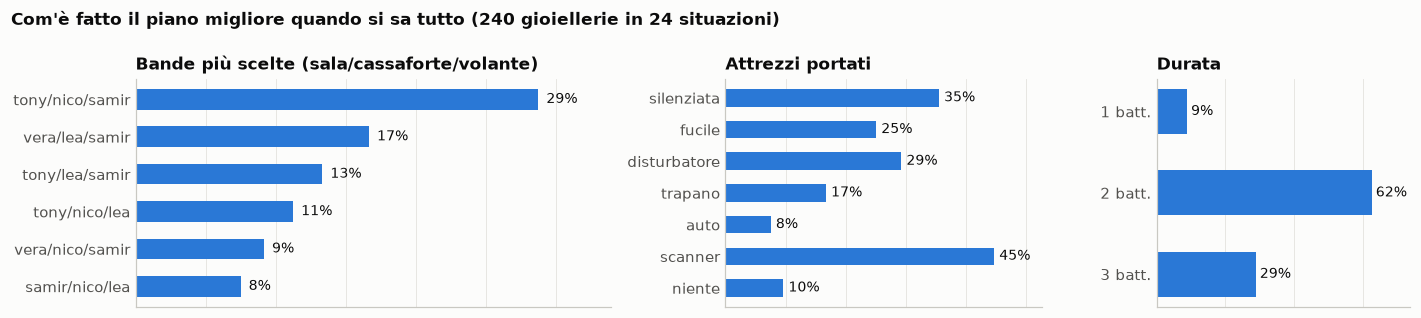

In [4]:
n = len(R)
print(f"Piani al buio diversi: {len(set(x['piano al buio'] for x in R))} su {n} situazioni.")
informati = [p for x in R for p in x["piani informati"]]
bande = collections.Counter(p.split(" · ")[0] for p in informati).most_common(6)
attrezzi = collections.Counter(a for p in informati for a in p.split(" · ")[1].split("+"))
battute = collections.Counter(p.split(" · ")[2] for p in informati)

fig, axs = plt.subplots(1, 3, figsize=(13, 2.9), gridspec_kw={"width_ratios": [1.5, 1, 0.8]})
barre(axs[0], [b for b, _ in bande], [v / len(informati) for _, v in bande], "Bande più scelte (sala/cassaforte/volante)")
chiavi = list(C.EQUIP) + ["niente"]
barre(axs[1], chiavi, [attrezzi[k] / len(informati) for k in chiavi], "Attrezzi portati")
bk = sorted(battute)
barre(axs[2], bk, [battute[k] / len(informati) for k in bk], "Durata")
fig.suptitle(f"Com'è fatto il piano migliore quando si sa tutto ({len(informati)} gioiellerie in {n} situazioni)",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()
if bande[0][1] / len(informati) > 0.5:
    print(f"SEGNALE: la banda {bande[0][0]} è la scelta nel {bande[0][1]/len(informati):.0%} dei casi.")

## 4. I piani B scattano?

Si rigioca il piano al buio di ogni situazione su 300 gioiellerie a caso e si conta quanto spesso scatta ogni condizione.

**Cosa cercare:** condizioni che scattano né mai né sempre. Una condizione sotto il 5% è una casella di piano B sprecata.

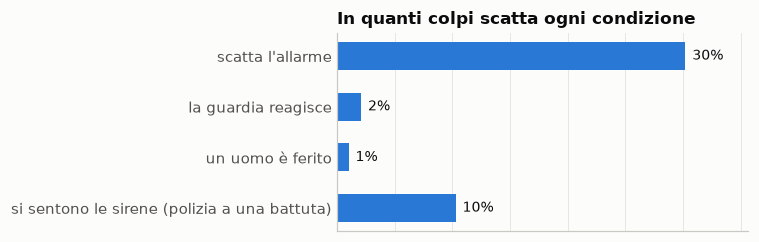

Panico (condizione scattata senza piano B, nervi saltati): 4% dei colpi.
SEGNALE: «la guardia reagisce» scatta solo nel 2% dei colpi.
SEGNALE: «un uomo è ferito» scatta solo nel 1% dei colpi.


In [5]:
r = random.Random(3)
tutti = []
for x in R:
    sc_x = C.genera_scenario(x["colpo"])
    tutti += [C.gioca(C.con_fatti(sc_x, C.fatti_a_caso(r)), x["piano"], r.random(), ISTINTO) for _ in range(300)]
freq = {c: sum(c in e.condizioni for e in tutti) / len(tutti) for c in C.CONDIZIONI}
fig, ax = plt.subplots(figsize=(7, 2.3))
barre(ax, [C.CONDIZIONI[c] for c in freq], list(freq.values()), "In quanti colpi scatta ogni condizione")
plt.tight_layout(); plt.show()
print(f"Panico (condizione scattata senza piano B, nervi saltati): {sum(e.panici > 0 for e in tutti)/len(tutti):.0%} dei colpi.")
for c, q in freq.items():
    if q < 0.05: print(f"SEGNALE: «{C.CONDIZIONI[c]}» scatta solo nel {q:.0%} dei colpi.")
    if q > 0.80: print(f"SEGNALE: «{C.CONDIZIONI[c]}» scatta nel {q:.0%} dei colpi: non è un imprevisto, è la norma.")

## Come usare questi numeri

Le simulazioni dicono se le regole **possono** reggere. Non dicono se il colpo **diverte**: tensione mentre guardi, voglia di rigiocare e voglia di raccontarlo si misurano solo giocando, e le partite salvate in `partite/` sono la prova che conta.